In [ ]:
%pip install matplotlib seaborn

In [32]:
import pandas as pd
import numpy as numpy
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

#load the csv and display the first five restaurant records
df=pd.read_csv("Zomato_Restaurant_Dataset_Cleaned.csv")
print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Dataset loaded successfully!
Rows: 9551
Columns: 22


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes,Rating Status
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Yes,No,No,No,3,4.8,Dark Green,Excellent,314,Rated
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Yes,No,No,No,3,4.5,Dark Green,Excellent,591,Rated
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Yes,No,No,No,4,4.4,Green,Very Good,270,Rated
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,No,No,No,No,4,4.9,Dark Green,Excellent,365,Rated
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Yes,No,No,No,4,4.8,Dark Green,Excellent,229,Rated


In [33]:
#inspect the dataset
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset dimensions: (9551, 22)

Column names:
['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes', 'Rating Status']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   str    
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   str    
 4   Address               9551 non-null   str    
 5   Locality              9551 non-null   str    
 6   Locality Verbose      9551 non-null   str    
 7   Longitude             9

,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


In [34]:
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


Total missing values: 0
Duplicate rows: 0


Average rating: 2.67
Median rating: 3.2
Highest rating: 4.9
Lowest rating: 0.0


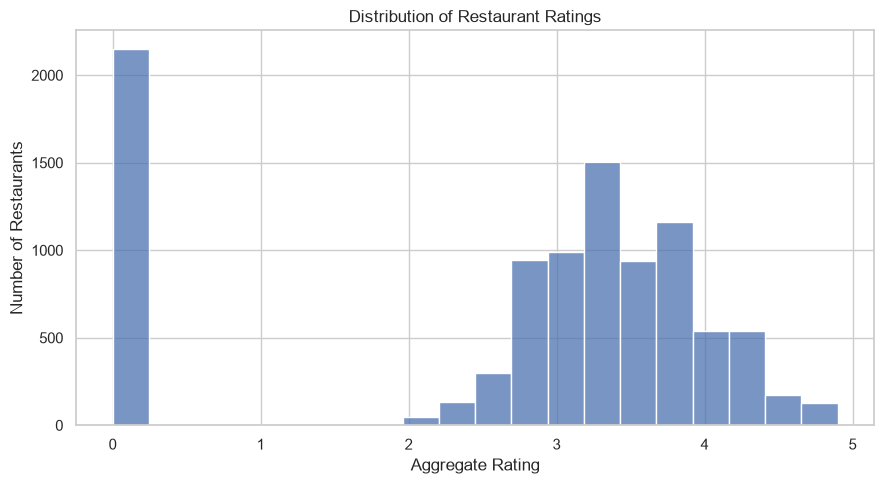

In [35]:
#Analyze restaurant ratings
print("Average rating:", round(df["Aggregate rating"].mean(), 2))
print("Median rating:", round(df["Aggregate rating"].median(), 2))
print("Highest rating:", df["Aggregate rating"].max())
print("Lowest rating:", df["Aggregate rating"].min())


#Rating distribution chart
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Aggregate rating",
    bins=20
)


plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Aggregate Rating")
plt.ylabel("Number of Restaurants")

plt.tight_layout()
plt.savefig(
    "restaurant_rating_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

,Restaurant Count
City,
New Delhi,5473
Gurgaon,1118
Noida,1080
Faridabad,251
Ghaziabad,25
Ahmedabad,21
Amritsar,21
Bhubaneshwar,21
Guwahati,21


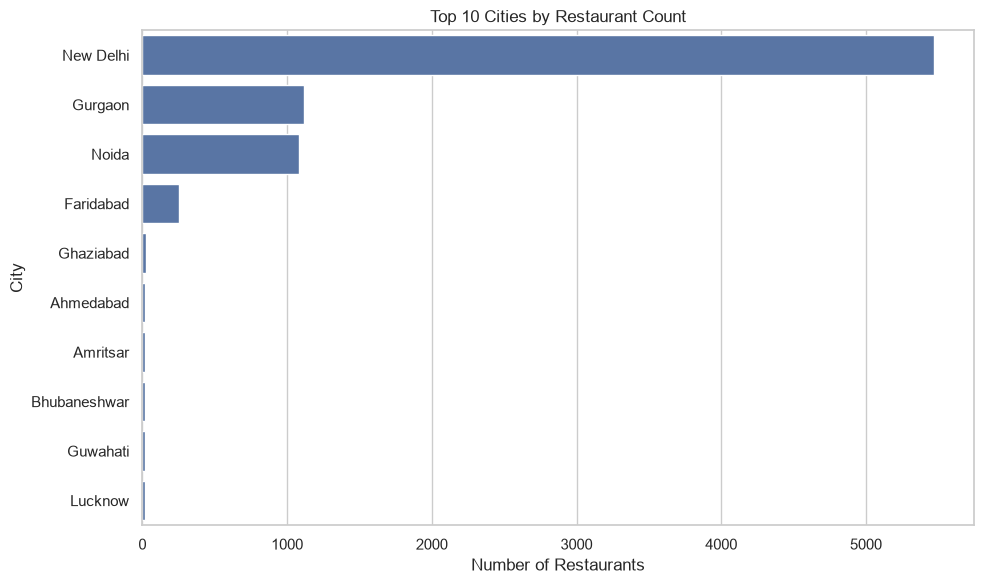

In [36]:
#Top 10 cities by restaurant count
top_cities = df["City"].value_counts().head(10)

display(top_cities.rename("Restaurant Count").to_frame())



#chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_cities.values,
    y=top_cities.index
)

plt.title("Top 10 Cities by Restaurant Count")
plt.xlabel("Number of Restaurants")
plt.ylabel("City")

plt.tight_layout()
plt.savefig("top_10_cuisines.png", dpi=300, bbox_inches="tight")
plt.show()


,Occurrences
Cuisines,
North Indian,3960
Chinese,2735
Fast Food,1986
Mughlai,995
Italian,764
Bakery,745
Continental,736
Cafe,703
Desserts,653


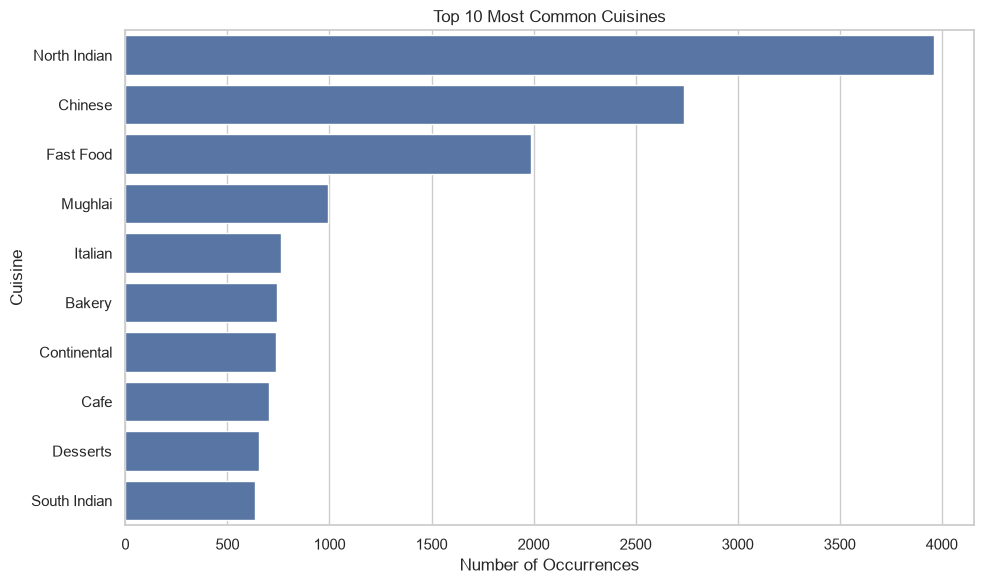

In [37]:
#Most popular cuisines
cuisine_counts = (
    df["Cuisines"]
    .dropna()
    .loc[lambda s: s.ne("Not Specified")]
    .str.split(",")
    .explode()
    .str.strip()
    .loc[lambda s: s.ne("")]
    .value_counts()
)

top_cuisines = cuisine_counts.head(10)

display(top_cuisines.rename("Occurrences").to_frame())


#chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_cuisines.values,
    y=top_cuisines.index
)

plt.title("Top 10 Most Common Cuisines")
plt.xlabel("Number of Occurrences")
plt.ylabel("Cuisine")

plt.tight_layout()
plt.savefig("top_10_cuisines.png", dpi=300, bbox_inches="tight")
plt.show()



,count,mean,median
Price range,,,
1,4444,2.00,2.9
2,3113,2.94,3.3
3,1408,3.68,3.8
4,586,3.82,3.9


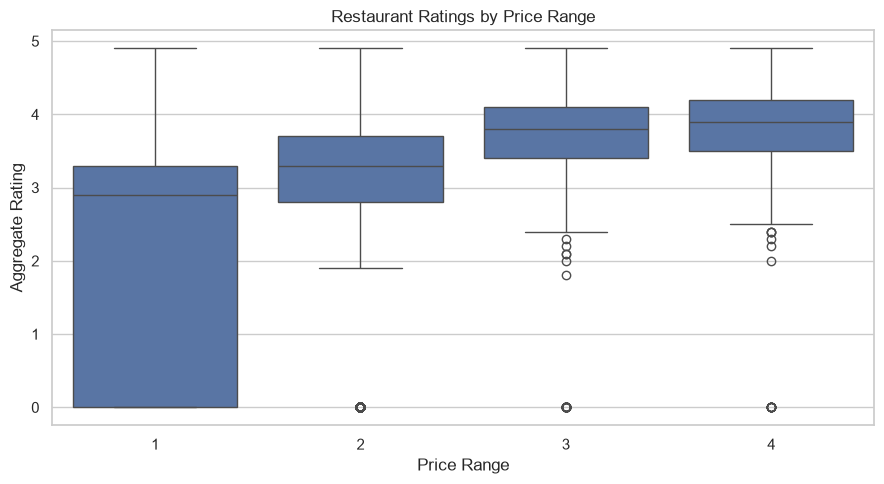

In [38]:
#compare ratings across price ranges
price_rating = (
    df.groupby("Price range")["Aggregate rating"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(price_rating)


#Box plot
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Price range",
    y="Aggregate rating"
)

plt.title("Restaurant Ratings by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Aggregate Rating")

plt.tight_layout()
plt.savefig("ratings_by_price_range.png", dpi=300, bbox_inches="tight")
plt.show()


,Count,Percentage
Has Online delivery,,
No,7100,74.34
Yes,2451,25.66


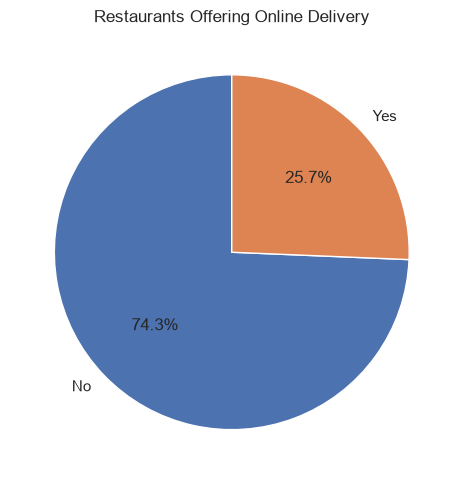

In [39]:
#Analyze online delivery
delivery_counts = df["Has Online delivery"].value_counts(dropna=False)

delivery_percentages = (
    df["Has Online delivery"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

delivery_summary = pd.DataFrame({
    "Count": delivery_counts,
    "Percentage": delivery_percentages
})

display(delivery_summary)



#Chart
delivery_plot = df["Has Online delivery"].value_counts()

plt.figure(figsize=(7, 5))

plt.pie(
    delivery_plot.values,
    labels=delivery_plot.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Restaurants Offering Online Delivery")
plt.tight_layout()
plt.savefig("online_delivery_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


,Count,Percentage
Has Table booking,,
No,8393,87.88
Yes,1158,12.12


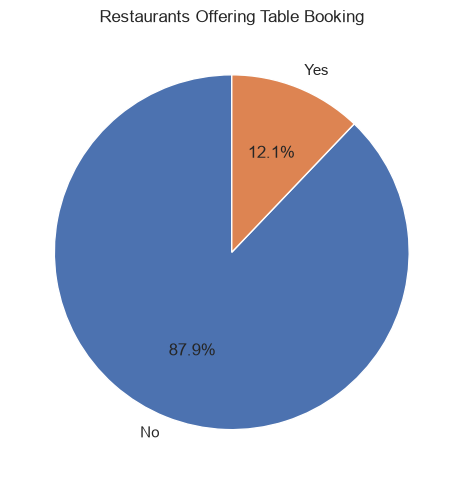

In [40]:
#Analyze table booking
booking_counts = df["Has Table booking"].value_counts(dropna=False)

booking_percentages = (
    df["Has Table booking"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

booking_summary = pd.DataFrame({
    "Count": booking_counts,
    "Percentage": booking_percentages
})

display(booking_summary)



#chart
booking_plot = df["Has Table booking"].value_counts()

plt.figure(figsize=(7, 5))

plt.pie(
    booking_plot.values,
    labels=booking_plot.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Restaurants Offering Table Booking")
plt.tight_layout()
plt.savefig("table_booking_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


Average cost for two: 1199.21
Median cost for two: 400.0
Maximum cost for two: 800000


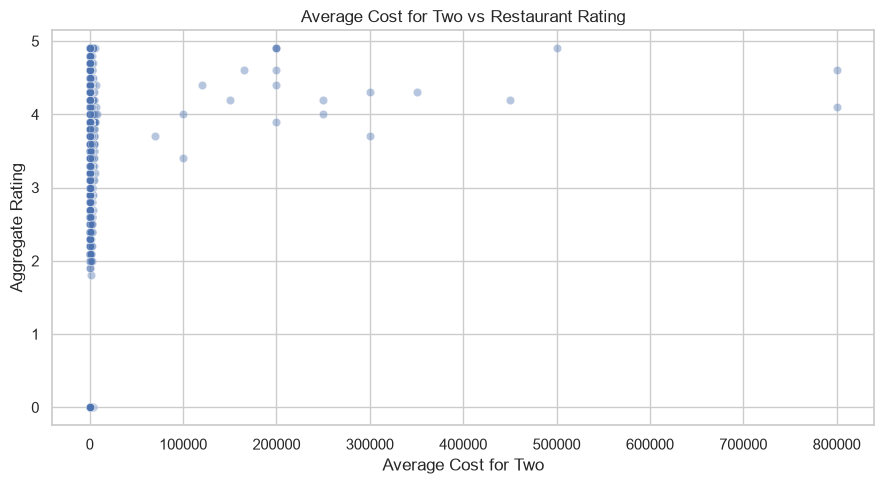

In [41]:
#Analyze restaurants cost and ratings
print(
    "Average cost for two:",
    round(df["Average Cost for two"].mean(), 2)
)

print(
    "Median cost for two:",
    round(df["Average Cost for two"].median(), 2)
)

print(
    "Maximum cost for two:",
    df["Average Cost for two"].max()
)

#Scatter plot
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Average Cost for two",
    y="Aggregate rating",
    alpha=0.4
)

plt.title("Average Cost for Two vs Restaurant Rating")
plt.xlabel("Average Cost for Two")
plt.ylabel("Aggregate Rating")

plt.tight_layout()
plt.savefig("cost_vs_rating.png", dpi=300, bbox_inches="tight")
plt.show()


Q1: 250.0
Q3: 700.0
IQR: 450.0
Lower limit: -425.0
Upper limit: 1375.0
Potential cost outliers: 853


,Restaurant Name,Country Code,Average Cost for two,Currency
2,Heat - Edsa Shangri-La,162,4000,Botswana Pula(P)
3,Ooma,162,1500,Botswana Pula(P)
4,Sambo Kojin,162,1500,Botswana Pula(P)
6,Buffet 101,162,2000,Botswana Pula(P)
7,Vikings,162,2000,Botswana Pula(P)
8,Spiral - Sofitel Philippine Plaza Manila,162,6000,Botswana Pula(P)
19,Wildflour Cafe + Bakery,162,1500,Botswana Pula(P)
20,NIU by Vikings,162,3000,Botswana Pula(P)
21,The Food Hall by Todd English,162,1800,Botswana Pula(P)
629,MoMo Cafe,1,2000,Indian Rupees(Rs.)


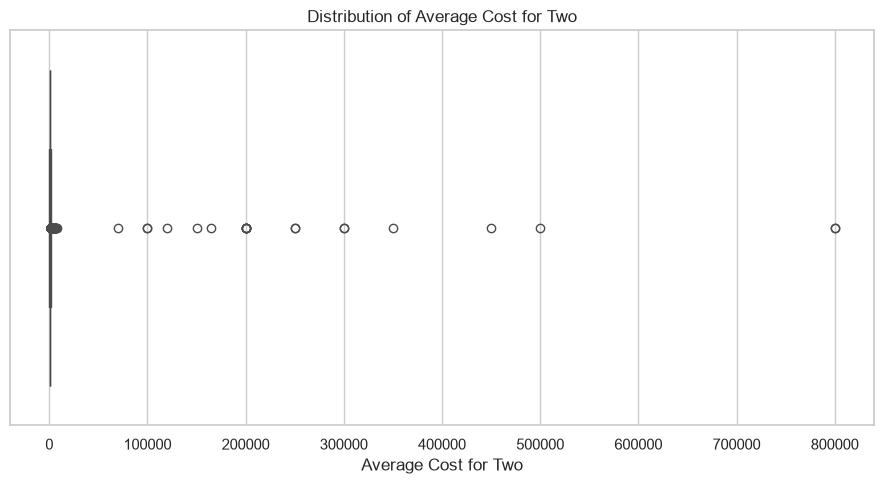

Ratings outside 0–5: 0
Negative vote counts: 0


In [42]:
#Identified potential anomalies
cost = df["Average Cost for two"].dropna()

Q1 = cost.quantile(0.25)
Q3 = cost.quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

cost_anomalies = df[
    (df["Average Cost for two"] < lower_limit) |
    (df["Average Cost for two"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Potential cost outliers:", len(cost_anomalies))

display(
    cost_anomalies[
        [
            "Restaurant Name",
            "Country Code",
            "Average Cost for two",
            "Currency"
        ]
    ].head(10)
)

plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Average Cost for two")

plt.title("Distribution of Average Cost for Two")
plt.xlabel("Average Cost for Two")

plt.tight_layout()
plt.savefig("cost_outliers.png", dpi=300, bbox_inches="tight")
plt.show()



#Invalid ratings and negative votes
invalid_ratings = df[
    df["Aggregate rating"].notna() &
    ~df["Aggregate rating"].between(0, 5)
]

negative_votes = df[
    df["Votes"].notna() &
    (df["Votes"] < 0)
]

print("Ratings outside 0–5:", len(invalid_ratings))
print("Negative vote counts:", len(negative_votes))




In [43]:
#Insights generation



# Insight 1: City with the most listings
city_counts = df["City"].dropna().value_counts()

if not city_counts.empty:
    print(
        f"1. City with the most listings: {city_counts.index[0]} "
        f"({city_counts.iloc[0]} restaurants)."
    )

# Insight 2: Most common cuisine
if not top_cuisines.empty:
    print(
        f"2. Most common cuisine: {top_cuisines.index[0]} "
        f"({top_cuisines.iloc[0]} occurrences)."
    )

# Insight 3: Most common rating category
rating_counts = df["Rating text"].dropna().value_counts()

if not rating_counts.empty:
    print(
        f"3. Most common rating category: {rating_counts.index[0]} "
        f"({rating_counts.iloc[0]} restaurants)."
    )

# Insight 4: Online delivery availability
delivery_pct = (
    df["Has Online delivery"]
    .value_counts(normalize=True)
    .mul(100)
)

if not delivery_pct.empty:
    print(
        f"4. Most common online-delivery status: {delivery_pct.index[0]} "
        f"({delivery_pct.iloc[0]:.2f}%)."
    )

# Insight 5: Price range with the highest average rating
mean_ratings = (
    df.groupby("Price range")["Aggregate rating"]
    .mean()
    .dropna()
)

if not mean_ratings.empty:
    print(
        f"5. Price range with the highest average rating: "
        f"{mean_ratings.idxmax()} "
        f"(average rating {mean_ratings.max():.2f})."
    )

1. City with the most listings: New Delhi (5473 restaurants).
2. Most common cuisine: North Indian (3960 occurrences).
3. Most common rating category: Average (3737 restaurants).
4. Most common online-delivery status: No (74.34%).
5. Price range with the highest average rating: 4 (average rating 3.82).


In [44]:
#save the results

top_cities.rename("Restaurant Count").to_csv("top_cities.csv")

top_cuisines.rename("Occurrences").to_csv("top_cuisines.csv")

price_rating.to_csv("ratings_by_price_range.csv")

df["Rating text"].value_counts(dropna=False).to_csv(
    "rating_distribution.csv"
)

print("EDA summary tables saved successfully!")

EDA summary tables saved successfully!
